In [1]:
import numpy as np
import pandas as pd
from scipy.stats import kurtosis, skew
from scipy.fft import fft
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from keras import Sequential
from keras.layers import LSTM, Dense, Dropout
from keras.utils import to_categorical
from sklearn.metrics import classification_report
from keras.models import save_model, load_model

In [2]:
data = pd.read_csv("C:/Users/Jeremy S Obozuwa/Desktop/fine_proj/fault_conditions_dataset.csv")
data = pd.DataFrame(data)
data.head()

,accX,accY,accZ,temp,hum,sound,Time,Condition
0,-8.637833,-1.391765,22.527637,37.154200,61.822475,51.379356,0:00:00,Normal Operation
1,-6.986874,-0.718559,24.930535,37.708540,60.812437,51.780462,0:00:01,Normal Operation
2,-7.024152,-1.064274,24.441273,38.826935,61.271868,53.891260,0:00:02,Normal Operation
3,-7.710601,-0.644423,27.961503,36.968175,61.767500,51.781186,0:00:03,Normal Operation
4,-8.071165,-1.381348,27.426877,38.811712,60.756372,50.012469,0:00:04,Normal Operation


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 140000 entries, 0 to 139999
Data columns (total 8 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   accX       140000 non-null  float64
 1   accY       140000 non-null  float64
 2   accZ       140000 non-null  float64
 3   temp       140000 non-null  float64
 4   hum        140000 non-null  float64
 5   sound      140000 non-null  float64
 6   Time       140000 non-null  object 
 7   Condition  140000 non-null  object 
dtypes: float64(6), object(2)
memory usage: 8.5+ MB


In [4]:
conditions = ["Normal Operation", "Misalignment", "Bearing Fault", "Imbalance", "Overheating", "Lubrication Failure", "Electrical Fault"]
label_mapping = {label: idx for idx, label in enumerate(conditions)}
data['Condition'] = data['Condition'].map(label_mapping)
print(data['Condition'])

0         0
1         0
2         0
3         0
4         0
         ..
139995    6
139996    6
139997    6
139998    6
139999    6
Name: Condition, Length: 140000, dtype: int64


In [5]:
print(data['Condition'].unique())

[0 1 2 3 4 5 6]


In [6]:
import numpy as np
import pandas as pd
import scipy.stats as stats
from scipy.fftpack import fft

def extract_features(data):
    features = []

    for i in range(len(data)):
        row = data.iloc[i]

        accX = np.array([row['accX']])
        accY = np.array([row['accY']])
        accZ = np.array([row['accZ']])
        sound = np.array([row['sound']])

        # Ensure arrays are not empty before processing
        if accX.size == 0 or accY.size == 0 or accZ.size == 0 or sound.size == 0:
            # Handle the empty array situation (e.g., skip this row)
            continue

        # Time-domain features (only if arrays are not empty)
        time_features = {
            "mean_accX": np.mean(accX),
            "mean_accY": np.mean(accY),
            "mean_accZ": np.mean(accZ),
            "mean_sound": np.mean(sound),
            "rms_accX": np.sqrt(np.mean(accX**2)),
            "rms_accY": np.sqrt(np.mean(accY**2)),
            "rms_accZ": np.sqrt(np.mean(accZ**2)),
            "rms_sound": np.sqrt(np.mean(sound**2)),
            "kurtosis_accX": stats.kurtosis(accX),
            "kurtosis_accY": stats.kurtosis(accY),
            "kurtosis_accZ": stats.kurtosis(accZ),
            "kurtosis_sound": stats.kurtosis(sound),
            "skewness_accX": stats.skew(accX),
            "skewness_accY": stats.skew(accY),
            "skewness_accZ": stats.skew(accZ),
            "skewness_sound": stats.skew(sound),
            "temp": row['temp'],
            "hum": row['hum'],
            "sound": row['sound'],
        }

        

        # Find max frequency
        sampling_rate = 1000  # Adjust this based on your data acquisition rate

        # Frequency-domain features using FFT (check that array is not empty)
        accX_fft = np.fft.fft(accX) 
        accY_fft = np.fft.fft(accY)
        accZ_fft = np.fft.fft(accZ) 
        sound_fft = np.fft.fft(sound) 

        magnitudeX = np.abs(accX_fft)
        magnitudeY = np.abs(accY_fft)
        magnitudeZ = np.abs(accZ_fft)
        magnitudeS = np.abs(sound_fft)

        max_indexX = np.argmax(magnitudeX)
        max_indexY = np.argmax(magnitudeY)
        max_indexZ = np.argmax(magnitudeZ)
        max_indexS = np.argmax(magnitudeS)

        normalized_magnitudeX = magnitudeX / np.sum(magnitudeX)
        normalized_magnitudeY = magnitudeY / np.sum(magnitudeY)
        normalized_magnitudeZ = magnitudeZ / np.sum(magnitudeZ)
        normalized_magnitudeS = magnitudeS / np.sum(magnitudeS)


        freq_features = {
            "max_freq_accX": max_indexX * sampling_rate / len(accX), 
            "max_freq_accY": max_indexY * sampling_rate / len(accY),
            "max_freq_accZ": max_indexZ * sampling_rate / len(accZ),
            "max_freq_sound": max_indexS * sampling_rate / len(sound),
            "spectral_entropy_accX": -np.sum(normalized_magnitudeX * np.log2(normalized_magnitudeX + 1e-10)),
            "spectral_entropy_accY": -np.sum(normalized_magnitudeY * np.log2(normalized_magnitudeY + 1e-10)),
            "spectral_entropy_accZ": -np.sum(normalized_magnitudeZ * np.log2(normalized_magnitudeZ + 1e-10)),
            "spectral_entropy_sound": -np.sum(normalized_magnitudeS * np.log2(normalized_magnitudeS + 1e-10)),
        }

        # Combine all features
        combined_features = {**time_features, **freq_features}
        features.append(combined_features)

        
    return pd.DataFrame(features)

In [7]:
# Extract X and Y columns
X = data[["accX", "accY", "accZ", "temp", "hum", "sound"]]
Y = data["Condition"]
len(X)

140000

In [8]:
X.head()

,accX,accY,accZ,temp,hum,sound
0,-8.637833,-1.391765,22.527637,37.154200,61.822475,51.379356
1,-6.986874,-0.718559,24.930535,37.708540,60.812437,51.780462
2,-7.024152,-1.064274,24.441273,38.826935,61.271868,53.891260
3,-7.710601,-0.644423,27.961503,36.968175,61.767500,51.781186
4,-8.071165,-1.381348,27.426877,38.811712,60.756372,50.012469


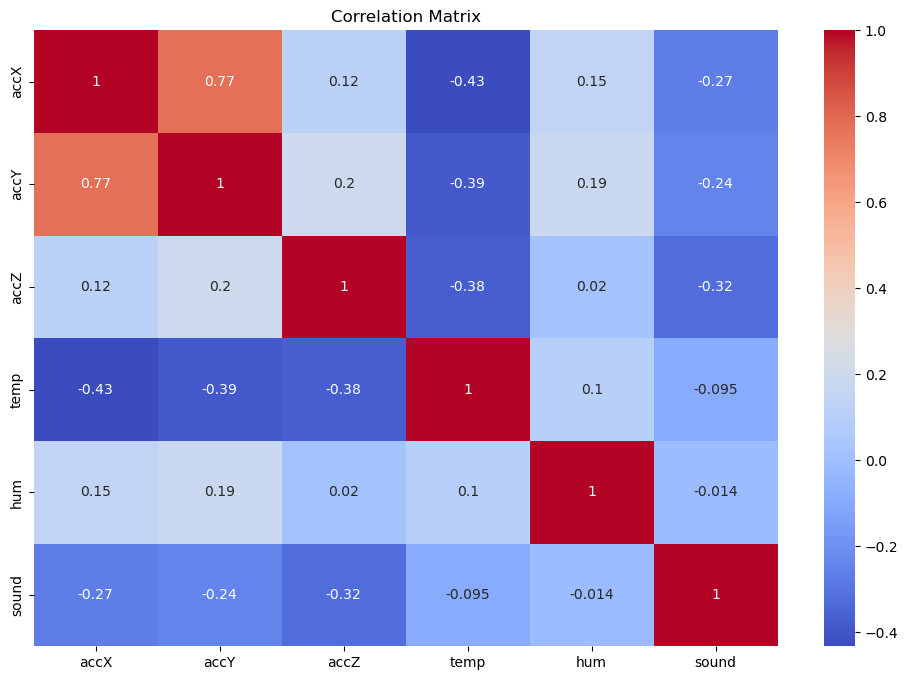

           accX      accY      accZ      temp       hum     sound
accX   1.000000  0.774278  0.120423 -0.432111  0.146388 -0.266210
accY   0.774278  1.000000  0.200784 -0.388919  0.185274 -0.243967
accZ   0.120423  0.200784  1.000000 -0.375693  0.020103 -0.324579
temp  -0.432111 -0.388919 -0.375693  1.000000  0.100221 -0.094930
hum    0.146388  0.185274  0.020103  0.100221  1.000000 -0.013963
sound -0.266210 -0.243967 -0.324579 -0.094930 -0.013963  1.000000


In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

correlation_matrix = X.corr()
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()
print(correlation_matrix)

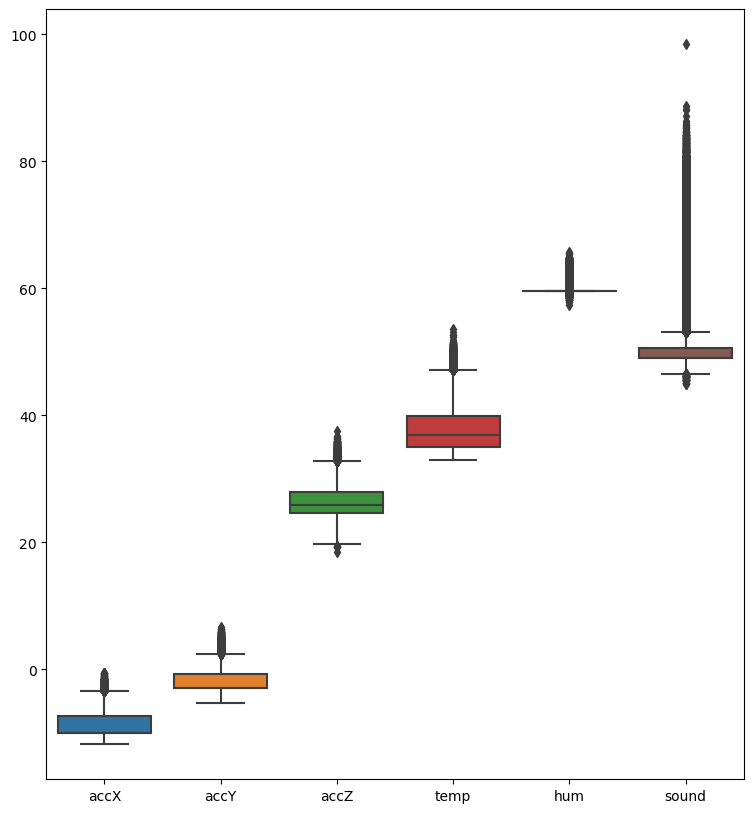

In [10]:
plt.figure(figsize=(9, 10))
sns.boxplot(X)
plt.show()


In [11]:
# Feature extraction
features = extract_features(X)
features = features.fillna(0)

# Labels
labels = data['Condition'].values


In [12]:
print(features.head())
features.tail()

features.to_csv("test1.csv", index=False)

   mean_accX  mean_accY  mean_accZ  mean_sound  rms_accX  rms_accY   rms_accZ  \
0  -8.637833  -1.391765  22.527637   51.379356  8.637833  1.391765  22.527637   
1  -6.986874  -0.718559  24.930535   51.780462  6.986874  0.718559  24.930535   
2  -7.024152  -1.064274  24.441273   53.891260  7.024152  1.064274  24.441273   
3  -7.710601  -0.644423  27.961503   51.781186  7.710601  0.644423  27.961503   
4  -8.071165  -1.381348  27.426877   50.012469  8.071165  1.381348  27.426877   

   rms_sound  kurtosis_accX  kurtosis_accY  ...        hum      sound  \
0  51.379356            0.0            0.0  ...  61.822475  51.379356   
1  51.780462            0.0            0.0  ...  60.812437  51.780462   
2  53.891260            0.0            0.0  ...  61.271868  53.891260   
3  51.781186            0.0            0.0  ...  61.767500  51.781186   
4  50.012469            0.0            0.0  ...  60.756372  50.012469   

   max_freq_accX  max_freq_accY  max_freq_accZ  max_freq_sound  \
0       

In [13]:

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(features, labels, test_size=0.2, random_state=42)


In [14]:
# Standardize features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [15]:
from sklearn.preprocessing import LabelEncoder

# Create a LabelEncoder instance
le = LabelEncoder()

# Combine labels from both train and test to ensure consistency in encoding
all_labels = np.concatenate([y_train, y_test])

# Fit the encoder to all labels
le.fit(all_labels)

# Transform the labels into integers
y_train_int = le.transform(y_train)
y_test_int = le.transform(y_test)

# Calculate the number of unique classes based on all labels
num_classes = len(np.unique(all_labels))

# Apply to_categorical to the integer labels
y_train = to_categorical(y_train_int, num_classes=num_classes)
y_test = to_categorical(y_test_int, num_classes=num_classes)


In [20]:
# Build the LSTM model
model = Sequential()

In [21]:

# LSTM layer
model.add(LSTM(units=128, input_shape=(X_train.shape[1], 1), return_sequences=False))
model.add(Dropout(0.5))  # Dropout for regularization

In [22]:
# Dense output layer with softmax for classification
model.add(Dense(units=num_classes, activation='softmax'))

# Compile the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])


In [23]:
# Train the model
history = model.fit(X_train.reshape(X_train.shape[0], X_train.shape[1], 1), y_train, epochs=20, batch_size=32, validation_data=(X_test.reshape(X_test.shape[0], X_test.shape[1], 1), y_test))


Epoch 1/20
3500/3500 ━━━━━━━━━━━━━━━━━━━━ 111s 30ms/step - accuracy: 0.9230 - loss: 0.2432 - val_accuracy: 0.9929 - val_loss: 0.0264
Epoch 2/20
3500/3500 ━━━━━━━━━━━━━━━━━━━━ 104s 30ms/step - accuracy: 0.9918 - loss: 0.0350 - val_accuracy: 0.9428 - val_loss: 0.2774
Epoch 3/20
3500/3500 ━━━━━━━━━━━━━━━━━━━━ 106s 30ms/step - accuracy: 0.9944 - loss: 0.0251 - val_accuracy: 0.9974 - val_loss: 0.0126
Epoch 4/20
3500/3500 ━━━━━━━━━━━━━━━━━━━━ 104s 30ms/step - accuracy: 0.9966 - loss: 0.0167 - val_accuracy: 0.9979 - val_loss: 0.0106
Epoch 5/20
3500/3500 ━━━━━━━━━━━━━━━━━━━━ 109s 31ms/step - accuracy: 0.9966 - loss: 0.0167 - val_accuracy: 0.9979 - val_loss: 0.0113
Epoch 6/20
3500/3500 ━━━━━━━━━━━━━━━━━━━━ 112s 32ms/step - accuracy: 0.9973 - loss: 0.0127 - val_accuracy: 0.9983 - val_loss: 0.0085
Epoch 7/20
3500/3500 ━━━━━━━━━━━━━━━━━━━━ 115s 33ms/step - accuracy: 0.9974 - loss: 0.0120 - val_accuracy: 0.9983 - val_loss: 0.0073
Epoch 8/20
3500/3500 ━━━━━━━━━━━━━━━━━━━━ 111s 32ms/step - accuracy: 

In [24]:
from keras.models import load_model
import joblib
# Save scaler and model using joblib
joblib.dump(scaler, 'new_vector2.pkl')
model.save('new_model2.h5')  # Use Keras's save method

# Load scaler and model using joblib and Keras
scaler = joblib.load('new_vector2.pkl')
model = load_model('new_model2.h5')


In [25]:
# Predict the labels using the model
y_pred = model.predict(X_test.reshape(X_test.shape[0], X_test.shape[1], 1))
y_pred_classes = np.argmax(y_pred, axis=1)
y_test_classes = np.argmax(y_test, axis=1)

# Define the condition labels (adjust according to your dataset)
conditions = ["Normal Operation", "Misalignment", "Bearing Fault", "Imbalance", 
              "Overheating", "Lubrication Failure", "Electrical Fault"]

# Print the predicted probabilities for the first sample
print("Predicted probabilities for the first sample:", y_pred[0])

# Get the predicted class for the first sample
predicted_class_index = np.argmax(y_pred[0])

# Get the corresponding condition for the predicted class
predicted_condition = conditions[predicted_class_index]

# Print the predicted condition for the first sample
print("Predicted condition for the first sample:", predicted_condition)


875/875 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step
Predicted probabilities for the first sample: [1.5564130e-07 4.2171891e-07 9.9997771e-01 2.1419339e-05 9.8200857e-08
 7.3691155e-08 1.7422904e-07]
Predicted condition for the first sample: Bearing Fault


In [26]:
# Print the input shape expected by the model
print("Model input shape:", model.input_shape)

# Print the shape of X_test before reshaping
print("Shape of X_test before reshaping:", X_test.shape)

# Check the reshaped X_test
print("Shape of X_test after reshaping:", X_test.reshape(X_test.shape[0], X_test.shape[1], 1).shape)


Model input shape: (None, 27, 1)
Shape of X_test before reshaping: (28000, 27)
Shape of X_test after reshaping: (28000, 27, 1)


In [27]:
# Define the condition labels (adjust according to your dataset)
conditions = ["Normal Operation", "Misalignment", "Bearing Fault", "Imbalance", 
              "Overheating", "Lubrication Failure", "Electrical Fault"]

# Specify labels corresponding to the conditions
# Ensure you have the full range of class labels, e.g., [0, 1, 2, 3, 4, 5, 6]
labels = np.arange(len(conditions))

# Print the classification report, using the full set of labels and target names
print(classification_report(y_test_classes, y_pred_classes, labels=labels, target_names=conditions))


                     precision    recall  f1-score   support

   Normal Operation       1.00      1.00      1.00      3965
       Misalignment       1.00      1.00      1.00      4099
      Bearing Fault       1.00      1.00      1.00      4023
          Imbalance       1.00      1.00      1.00      4057
        Overheating       1.00      1.00      1.00      3979
Lubrication Failure       1.00      1.00      1.00      3943
   Electrical Fault       1.00      1.00      1.00      3934

           accuracy                           1.00     28000
          macro avg       1.00      1.00      1.00     28000
       weighted avg       1.00      1.00      1.00     28000



In [28]:
# Function to extract features for new data
def extract_and_predict(new_data):
    # Extract features from new data
    features_new = extract_features(new_data)
    
    # Load the scaler and model
    # scaler = joblib.load('scaler.save')
    # model = joblib.load_model('fault_predictionl_model.h5')
    
    # scaler=pickle.load(open('vector1.pkl', 'rb'))
    # model=pickle.load(open('model1.pkl', 'rb'))

    # Standardize the new features
    features_new_scaled = scaler.transform(features_new)
    
    # Reshape for LSTM input
    features_new_scaled = features_new_scaled.reshape(features_new_scaled.shape[0], features_new_scaled.shape[1], 1)
    
    # Predict the condition
    predictions = model.predict(features_new_scaled)
    predicted_classes = np.argmax(predictions, axis=1)
    
    return predicted_classes

In [29]:
# Example usage:
new_data = pd.DataFrame({
    'accX': [-6.55, -0.034567],
    'accY': [1.45, 0.023456],
    'accZ': [22.71, 0.012345],
    'temp': [32.00, 41.56789],
    'hum': [59.60, 52.34567],
    'sound': [49, 59.76543],
})

In [30]:
# Extract features from new data 
Nx = extract_features(new_data)

# Fill missing values (NaN) with 0
Nx = Nx.fillna(0)

# Scale the new data using the previously fitted scaler
Nx = scaler.transform(Nx)

# Check the input shape of the model and reshape Nx if necessary
print("Expected model input shape:", model.input_shape)
print("Shape of Nx before reshaping:", Nx.shape)

# If the model expects 3D input, reshape Nx
if len(model.input_shape) == 3 and Nx.ndim == 2:
    Nx = Nx.reshape(Nx.shape[0], Nx.shape[1], 1)
    print("Shape of Nx after reshaping:", Nx.shape)

# Make predictions
new_rslt = model.predict(Nx)

# Condition labels
conditions = ["Normal Operation", "Misalignment", "Bearing Fault", "Imbalance", 
              "Overheating", "Lubrication Failure", "Electrical Fault"]

# Step 1: Convert predicted probabilities to class indices using np.argmax
predicted_classes = np.argmax(new_rslt, axis=1)  # Use axis=1 to get class index for each sample

# Step 2: Map predicted class indices to actual condition labels
predicted_conditions = [conditions[class_index] for class_index in predicted_classes]

# Step 3: Print the predicted probabilities and conditions for each sample
for i, (probs, condition) in enumerate(zip(new_rslt, predicted_conditions)):
    print(f"Sample {i+1}:")
    print(f"Predicted probabilities: {probs}")
    print(f"Predicted condition: {condition}\n")


Expected model input shape: (None, 27, 1)
Shape of Nx before reshaping: (2, 27)
Shape of Nx after reshaping: (2, 27, 1)
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 638ms/step
Sample 1:
Predicted probabilities: [5.3361317e-05 1.3073623e-02 4.2294479e-05 9.8670363e-01 3.7218255e-05
 6.2685205e-05 2.7201788e-05]
Predicted condition: Imbalance

Sample 2:
Predicted probabilities: [0.76867557 0.1052421  0.02402028 0.08815742 0.00546091 0.00145726
 0.00698648]
Predicted condition: Normal Operation

